# 3 · Feedback, saved results, and the dashboard code

**Question:** How is the planned swing-up executed, stabilized, tested, and shown in the dashboard?

This notebook reads the saved reference experiment, constructs upright LQR,
repeats disturbance tests, and explains the browser interface. It runs independently
of Notebook 2 and does not overwrite the saved results.
Estimated study time: 30–40 minutes.

Run cells from top to bottom using **Kernel → Restart Kernel and Run All Cells**.
Each notebook starts independently and imports the real project files. Python 3 with
the packages in `requirements-notebooks.txt` is required; see `README.txt` in this folder.
The delivered outputs were executed, not typed example results. Rerunning updates them.

In [1]:
from pathlib import Path
import sys, inspect, json, csv
from dataclasses import asdict, replace
import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Code, HTML, Image

# Works when Jupyter starts in this notebook folder, the project root,
# or the original workspace. No Windows-specific absolute path is needed.
def find_project():
    for parent in (Path.cwd(), *Path.cwd().parents):
        for candidate in (parent, parent / 'pendubot_simulation',
                          parent / 'Pendubot_Opt_Control',
                          parent / 'outputs' / 'pendubot_simulation',
                          parent / 'outputs' / 'Pendubot_Opt_Control'):
            if (candidate / 'pendubot.py').is_file():
                return candidate.resolve()
    raise FileNotFoundError('Keep notebooks/ inside the Pendubot project folder.')

PROJECT = find_project()
sys.path.insert(0, str(PROJECT))
from pendubot import Config, Solver, X0, GOAL, mass_matrix, dynamics, rk4, energy

def show_source(obj):
    # Display the actual implementation rather than a separately maintained copy.
    display(Code(inspect.getsource(obj), language='python'))

def show_table(rows, columns=None):
    if not rows:
        print('No rows.'); return
    columns = columns or list(rows[0])
    def fmt(value):
        if isinstance(value, (float, np.floating)):
            return f'{value:.6g}'
        return str(value)
    lines = ['| ' + ' | '.join(columns) + ' |',
             '| ' + ' | '.join(['---'] * len(columns)) + ' |']
    lines += ['| ' + ' | '.join(fmt(row.get(c, '')) for c in columns) + ' |'
              for row in rows]
    display(Markdown('\n'.join(lines)))

plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True,
                     'grid.alpha': 0.22, 'font.size': 11})
print('Python:', sys.version.split()[0], '| JAX:', jax.__version__)
print('JAX uses 64-bit arithmetic:', jax.config.x64_enabled)
print('Project located successfully.')

Python: 3.14.7 | JAX: 0.12.0.1
JAX uses 64-bit arithmetic: True
Project located successfully.


## 1. Understand the project files and data

| File | Role |
|---|---|
| `pendubot.py` | Model, integration, derivatives, DDP/iLQR |
| `run_simulation.py` | Model checks, comparisons, LQR, execution, metrics, plots and report |
| `interface.py` | Parameter validation, background solver jobs, execution, local HTTP service |
| `interface.html`, `.js`, `.css` | Form, animation, convergence chart, playback, appearance |
| `launcher.py` | Install/start the local application |
| `results/*.npz` | Arrays: states, controls, gains |
| `results/*_convergence.csv` | Accepted optimizer history |
| `results/summary.json` | Settings, versions, checks and measured results |

Saved data and fresh reruns are identified separately below. There is no need to
run the full batch script just to explore the reference result.

In [2]:
RESULTS = PROJECT / 'results'
summary = json.loads((RESULTS/'summary.json').read_text(encoding='utf-8'))
saved_cfg = dict(summary['config'])
saved_cfg['q'] = tuple(saved_cfg['q'])
saved_cfg['q_terminal'] = tuple(saved_cfg['q_terminal'])
cfg = Config(**saved_cfg)
solver = Solver(cfg)
selected = summary['selected']
with np.load(RESULTS/f'{selected}.npz', allow_pickle=False) as arrays:
    nominal = {key: arrays[key].copy() for key in ('x', 'u', 'gains')}
print('Saved selected plan:', selected)
print('State/control/gain shapes:', *(nominal[key].shape for key in ('x', 'u', 'gains')))
show_table(summary['comparison'], ['method', 'start', 'status', 'iterations', 'cost',
                                 'seconds_excluding_compile', 'peak_torque_nm'])
assert nominal['x'].shape == (cfg.n+1, 4)
assert nominal['u'].shape == (cfg.n, 1)

Saved selected plan: ddp_sine
State/control/gain shapes: (301, 4) (300, 1) (300, 1, 4)


| method | start | status | iterations | cost | seconds_excluding_compile | peak_torque_nm |
| --- | --- | --- | --- | --- | --- | --- |
| ddp | zero | converged | 698 | 5.17531 | 4.13223 | 26.9693 |
| ilqr | zero | converged | 594 | 5.17531 | 0.954477 | 26.9685 |
| ddp | sine | converged | 621 | 5.17531 | 3.48821 | 26.9693 |
| ilqr | sine | converged | 491 | 5.17531 | 0.726046 | 26.9685 |

## 2. Rebuild the convergence plot from CSV

This is the same quantity shown by the dashboard: objective against **accepted
optimization iteration**. It is independent of the animation timeline. Both curves
must use their own iteration values, since they can finish after different counts.
These are the saved reference runs, not timings measured in this notebook.

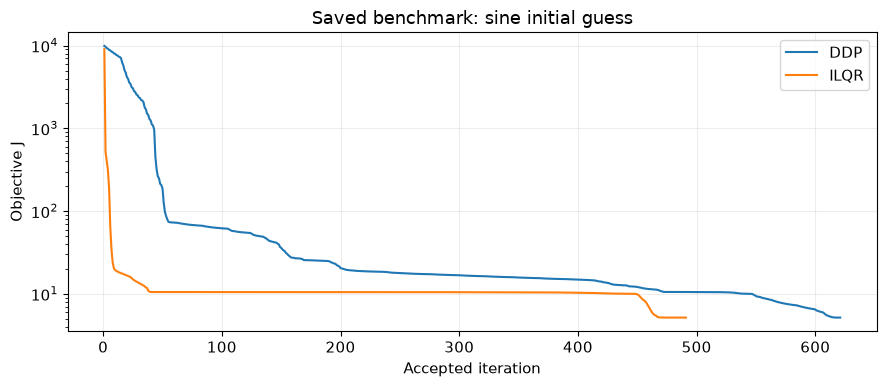

In [3]:
fig, ax = plt.subplots()
for method in ('ddp', 'ilqr'):
    with (RESULTS/f'{method}_sine_convergence.csv').open(newline='', encoding='utf-8') as stream:
        history = list(csv.DictReader(stream))
    ax.semilogy([int(row['iteration']) for row in history],
                [float(row['cost']) for row in history], label=method.upper())
ax.set(xlabel='Accepted iteration', ylabel='Objective J', title='Saved benchmark: sine initial guess')
ax.legend(); fig.tight_layout(); display(fig); plt.close(fig)

## 3. Trajectory feedback during swing-up

Before the planned horizon ends, use
$$u_k=\bar u_k-K_k(x_k-\bar x_k).$$
The nominal torque $\bar u_k$ supplies the planned motion. The state-dependent
term corrects deviations. `gains[k]` has shape `(1,4)` and maps four state errors
to a single torque correction. **Open loop** uses $\bar u_k$ alone.
These controls are sampled and held constant over each interval; fine integration
does not update feedback within those ten substeps.

At or after the horizon, both tested policies switch to the same local upright LQR.

In [4]:
sample = round(1. / cfg.dt)
deviation = np.array([.01, -.01, 0., 0.])
u_open = nominal['u'][sample]
u_feedback = u_open - nominal['gains'][sample] @ deviation
print('Example at 1 s, nominal input (N m):', float(u_open[0]))
print('For state error [0.01,-0.01,0,0], corrected input:', float(u_feedback[0]))

Example at 1 s, nominal input (N m): 3.271306270822802
For state error [0.01,-0.01,0,0], corrected input: 3.3599015029207093


## 4. Upright LQR: `make_lqr`

Linearize the discrete RK4 model at $(x_{goal},0)$:
$\delta x_{k+1}=A\delta x_k+B\delta u_k$.
Solve the discrete algebraic Riccati equation for $P$ using
$Q_L=\Delta t\,\mathrm{diag}(100,100,10,10)$ and $R_L=\Delta t[0.1]$:

$$P=Q_L+A^TPA-A^TPB(R_L+B^TPB)^{-1}B^TPA,$$
$$K_L=(R_L+B^TPB)^{-1}B^TPA,\qquad u=-K_L(x-x_{goal}).$$

The closed-loop spectral radius $\rho(A-BK_L)<1$ establishes stability of the
linearized sampled system. It does not guarantee nonlinear recovery from arbitrary states.
Negative numerical entries of $K_L$ are possible with this angle and input convention;
retain the explicit minus sign in the policy.

In [5]:
from run_simulation import make_lqr, execution, execution_metrics, errors
show_source(make_lqr)
klqr, radius = make_lqr(solver)
print('Upright LQR gain:', klqr)
print('Closed-loop spectral radius:', radius)
assert radius < 1

def make_lqr(solver):
    z = jnp.concatenate((GOAL, jnp.zeros(1)))
    jac = np.asarray(solver.derivatives(z[None])[0])
    a, b = jac[:, :4], jac[:, 4:]
    q = solver.cfg.dt*np.diag([100., 100., 10., 10.])
    r = solver.cfg.dt*np.array([[0.1]])
    p = solve_discrete_are(a, b, q, r)
    gain = np.linalg.solve(r+b.T@p@b, b.T@p@a)
    radius = float(np.max(np.abs(np.linalg.eigvals(a-b@gain))))
    assert radius < 1
    return gain, radius

Upright LQR gain: [[-146.04861639 -133.43716193  -61.58416774  -33.07725482]]
Closed-loop spectral radius: 0.9465512807853466


## 5. Read the execution loop

`execution` starts from rest or the specified initial offset. For the kick case,
it adds a velocity jump at 3 s. During the planned horizon, it applies nominal
control with optional trajectory feedback. Afterwards it uses `klqr` for 5 s.
`fine=True` selects ten RK4 substeps; `False` uses the optimizer's single-step map.

The initial offset is `[0.03,-0.02,0,0]`; the kick adds `[0,0,0.15,-0.10]`.
The guards stop a non-finite or excessively large state and fill subsequent
samples with NaNs so unavailable results cannot be mistaken for a good trajectory.

In [6]:
show_source(execution)

def execution(solver, nominal, klqr, feedback, fine, case):
    n, dt = solver.cfg.n, solver.cfg.dt
    x = np.zeros(4)
    if case == 'initial_offset':
        x += np.array([0.03, -0.02, 0., 0.])
    xs, us = [x.copy()], []
    termination_time = None
    integrate = solver.fine_step if fine else solver.step
    for k in range(n+round(5/dt)):
        # A velocity jump is an idealized instantaneous disturbance at t=3 s.
        if case == 'velocity_kick' and k == round(3/dt):
            x += np.array([0., 0., 0.15, -0.10])
            xs[-1] = x.copy()
        if k < n:
            u = nominal['u'][k].copy()
            if feedback:
                u -= nominal['gains'][k]@(x-nominal['x'][k])
        else:
            u = -klqr@(x-np.asarray(GOAL))
        with np.errstate(over='ignore', invalid='ignore'):
            x = np.asarray(integrate(jnp.array(x), jnp.array(u))).copy()
        xs.append(x.copy())
        us.append(float(u[0]))
        if not np.all(np.isfinite(x)) or np.max(np.abs(x)) > 1e5:
            termination_time = (k+1)*dt
            xs.extend([np.full(4, np.nan)]*(n+round(5/dt)-k-1))
            us.extend([np.nan]*(n+round(5/dt)-k-1))
            break
    return dict(x=np.asarray(xs), u=np.asarray(us), feedback=feedback, fine=fine, case=case,
                termination_time_s=termination_time)

## 6. Rerun the three disturbance cases with finer integration

The fresh runs below execute the saved plan on the current computer. They do
not re-optimize it and do not write files. A coarse nominal open-loop replay
first checks consistency with the optimizer's exact numerical model.

In [7]:
coarse_replay = execution(solver, nominal, klqr, feedback=False, fine=False, case='nominal')
replay_error = np.max(np.abs(coarse_replay['x'][:cfg.n+1]-nominal['x']))
print('Coarse nominal replay max state difference:', replay_error)
assert replay_error < 1e-8

runs, fresh_metrics = [], []
for case in ('nominal', 'initial_offset', 'velocity_kick'):
    for feedback in (False, True):
        run = execution(solver, nominal, klqr, feedback=feedback, fine=True, case=case)
        runs.append(run)
        fresh_metrics.append(execution_metrics(run, cfg.n))
show_table(fresh_metrics, ['case', 'policy', 'arrival_angle_error_rad',
                         'arrival_velocity_error_rad_s', 'swing_success', 'hold_success'])

Coarse nominal replay max state difference: 0.0


| case | policy | arrival_angle_error_rad | arrival_velocity_error_rad_s | swing_success | hold_success |
| --- | --- | --- | --- | --- | --- |
| nominal | open_loop | 2.39316 | 9.65298 | False | False |
| nominal | feedback | 4.09435e-08 | 1.65703e-07 | True | True |
| initial_offset | open_loop | 1.93245 | 11.6759 | False | False |
| initial_offset | feedback | 4.00542e-08 | 1.62071e-07 | True | True |
| velocity_kick | open_loop | 2.67636 | 6.39767 | False | False |
| velocity_kick | feedback | 1.11892e-05 | 4.37039e-05 | True | True |

## 7. Success metrics and error wrapping

Optimization uses the original unwrapped quadratic error. **Physical success**
wraps each angle error into $[-\pi,\pi)$ to identify equivalent orientations.
At arrival, each angle error must be below 0.05 rad and each angular velocity
error below 0.10 rad/s. During the full additional 5 s, each angle error must stay
below 0.10 rad and each velocity below 0.25 rad/s.

The chart below uses an angle-error **norm** for readability; success thresholds
are applied to the **maximum absolute component**, not this norm. `None` in the
metrics denotes an unavailable holding result for a terminated run.

def errors(x):
    e = np.asarray(x)-np.asarray(GOAL)
    physical = e.copy()
    physical[..., :2] = (physical[..., :2]+np.pi) % (2*np.pi)-np.pi
    return e, physical

def execution_metrics(result, n):
    e, physical = errors(result['x'])
    finite = bool(np.all(np.isfinite(result['x'])))
    angle = float(np.max(np.abs(physical[n, :2])))
    velocity = float(np.max(np.abs(physical[n, 2:])))
    hold_angle = float(np.max(np.abs(physical[n:, :2]))) if finite else None
    hold_velocity = float(np.max(np.abs(physical[n:, 2:]))) if finite else None
    return dict(case=result['case'], policy='feedback' if result['feedback'] else 'open_loop',
                integration='RK4_dt/10' if result['fine'] else 'RK4_dt', finite=finite,
                arrival_angle_error_rad=angle, arrival_velocity_error_rad_s=velocity,
                hold_max_angle_error_rad=hold_angle, hold_max_velocity_rad_s=hold_velocity,
                final_state_error_norm=float(np.linalg.norm(e[-1])) if finite else None,
                observed_peak_torque_nm=float(np.nanmax(np.abs(result['u']))),
                termination_time_s=result['termination_time_s'],
                swing_success=finite and angle < .05 and velocity < .10,
                hold_success=finite and hold_angle < .10 and hold_velocity < .25)

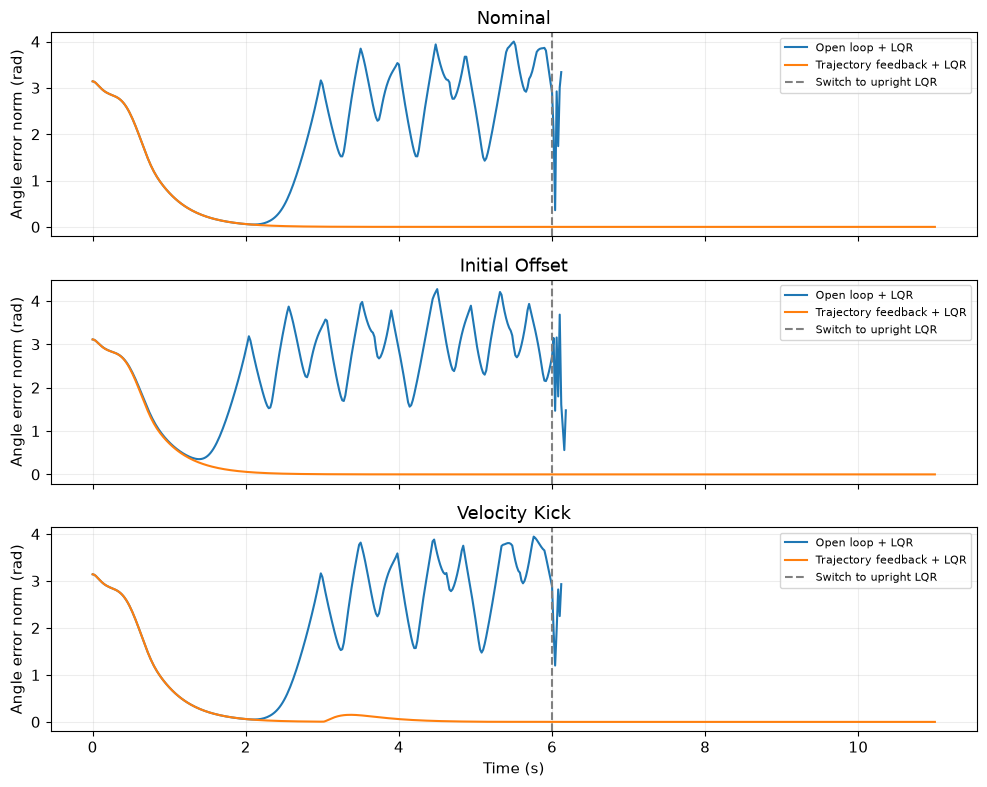

In [8]:
show_source(errors)
show_source(execution_metrics)
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for ax, case in zip(axes, ('nominal', 'initial_offset', 'velocity_kick')):
    for run in runs:
        if run['case'] == case:
            _, physical = errors(run['x'])
            label = 'Trajectory feedback + LQR' if run['feedback'] else 'Open loop + LQR'
            ax.plot(np.arange(len(physical))*cfg.dt, np.linalg.norm(physical[:, :2], axis=1), label=label)
    ax.axvline(cfg.duration, color='gray', ls='--', label='Switch to upright LQR')
    ax.set(title=case.replace('_', ' ').title(), ylabel='Angle error norm (rad)')
    ax.legend(fontsize=8)
axes[-1].set_xlabel('Time (s)')
fig.tight_layout(); display(fig); plt.close(fig)

### Interpreting the comparison

Exact same-model open-loop replay reproduces the nominal plan. Finer integration
introduces small model differences that can grow near the unstable upright state.
Feedback corrects deviations in the tested cases. These finite tests do not
establish a general robustness bound. Very large torques after failed arrival
come from applying local LQR outside its useful region; they are not credible
physical actuator requirements.

## 8. View the saved simulation animation

This GIF is the included reference animation, not regenerated by the fresh runs above.
It shows the fine-integration nominal feedback execution followed by upright LQR.

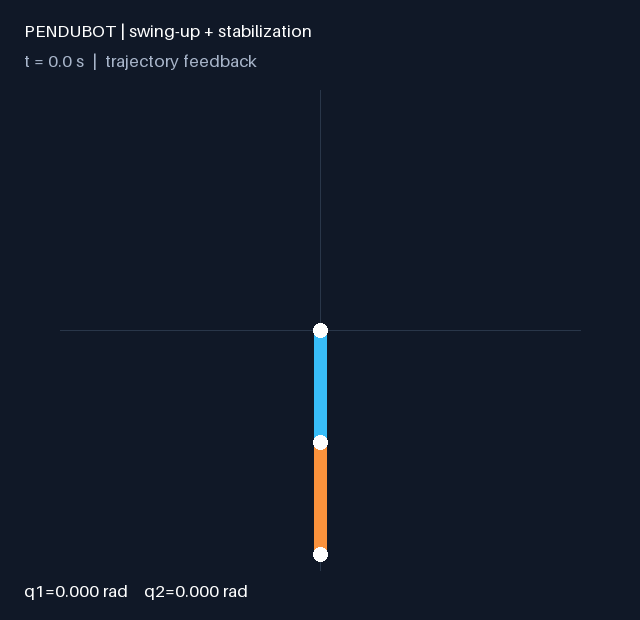

In [9]:
display(Image(filename=str(RESULTS/'swingup.gif')))

## 9. Dashboard parameter handling: `SCHEMA` and `validate`

`SCHEMA` defines labels, defaults, units, numeric ranges, and choices for the left
panel. `DEFAULTS` is built from it. `validate` fills missing values and rejects
invalid choices, non-finite values, out-of-range values, fractional integers,
incompatible time grids, and a nonzero kick outside the swing-up horizon.

Importing `interface` does not start a server: startup is under the module's
`if __name__ == '__main__'` guard. This notebook inspects the functions directly.

In [10]:
import interface as dashboard
show_table([{'section': group['title'],
             'editable settings': ', '.join(field['key'] for field in group['fields'])}
            for group in dashboard.SCHEMA])
settings = dashboard.validate({'method': 'both', 'r': .02})
print('Validated method:', settings['method'], '| Torque weight:', settings['r'])
try:
    dashboard.validate({'dt': .017})
except ValueError as exc:
    print('Example validation message:', exc)
show_source(dashboard.validate)

| section | editable settings |
| --- | --- |
| Simulation | method, duration, dt, hold, policy, integration, initial_guess, amplitude, period, max_iterations |
| Robot | m1, m2, l1, l2, gravity |
| Cost weights | q0, q1, q2, q3, qn0, qn1, qn2, qn3, r, lqr_r |
| Disturbances | offset0, offset1, offset2, offset3, kick_time, kick1, kick2 |
| Solver tolerances | relative_tolerance, control_tolerance |

Validated method: both | Torque weight: 0.02
Example validation message: Swing-up horizon must be an exact multiple of the sample interval.


def validate(raw):
    if not isinstance(raw, dict) or set(raw)-set(FIELDS):
        raise ValueError('Unrecognized parameter settings.')
    values = dict(DEFAULTS)
    for key, value in raw.items():
        field = FIELDS[key]
        if field['type'] == 'choice':
            if value not in [option[0] for option in field['options']]:
                raise ValueError('Choose a valid '+field['label']+'.')
        else:
            if isinstance(value, bool) or not isinstance(value, (int,float)) or not math.isfinite(value):
                raise ValueError(field['label']+' must be a finite number.')
            if not field['min'] <= value <= field['max']:
                raise ValueError(f"{field['label']} must be between {field['min']} and {field['max']}.")
            if field['type'] == 'integer' and value != int(value):
                raise ValueError(field['label']+' must be a whole number.')
            if field['type'] == 'integer':
                value = int(value)
            else:
                value = float(value)
        values[key] = value
    for label in ('duration', 'hold'):
        ratio = values[label]/values['dt']
        if abs(ratio-round(ratio)) > 1e-7:
            raise ValueError(('Swing-up horizon' if label == 'duration' else 'Hold time')+' must be an exact multiple of the sample interval.')
    if round(values['duration']/values['dt']) > 1200:
        raise ValueError('Use at most 1,200 swing-up samples: increase the sample interval or shorten the horizon.')
    if (values['kick1'] or values['kick2']) and values['kick_time'] >= values['duration']:
        raise ValueError('Place the nonzero velocity kick before the end of swing-up.')
    return values

## 10. What happens after “Run simulation”?

1. `interface.js` sends the settings to `POST /api/run`.
2. `Handler.do_POST` validates them and starts a background `worker` thread.
3. `worker` builds `Config`, compiles the solver, runs the selected methods,
   selects the lowest-cost plan, and calls `execute` for motion and holding.
4. The payload contains `comparison`, `history`, `nominal_x`, `nominal_u`, and
   `execution`. `interface_runs/latest.json` stores the last completed dashboard run.
5. The browser polls status/result endpoints and draws the returned motion and
   convergence histories. Playback speed changes the display, not the computed dynamics.

`execute` uses editable dashboard hold time, offsets, kick, integration fidelity,
and holding torque weight. The batch `execution` function uses the fixed reference
experiment settings. They share the same dynamics and policy conventions.
The following cell displays `worker`; it does not call it or create a run file.

In [11]:
show_source(dashboard.worker)

def worker(settings):
    try:
        update('Preparing model and derivatives…')
        import numpy as np
        from pendubot import Config, Solver
        cfg = Config(**{k:settings[k] for k in ('dt','duration','m1','m2','l1','l2','gravity',
                        'r','max_iterations','relative_tolerance','control_tolerance')},
                     q=tuple(settings['q'+str(i)] for i in range(4)),
                     q_terminal=tuple(settings['qn'+str(i)] for i in range(4)))
        solver = Solver(cfg)
        update('Compiling the model for these settings…')
        solver.warmup()
        t = np.arange(cfg.n)*cfg.dt
        u0 = settings['amplitude']*np.sin(2*np.pi*t/settings['period']) if settings['initial_guess']=='sine' else np.zeros(cfg.n)
        methods = ['ddp','ilqr'] if settings['method']=='both' else [settings['method']]
        solutions, comparison = {}, []
        for method in methods:
            update('Optimizing '+method.upper()+'…')
            result = solver.solve(u0,method,progress_callback=lambda i,c,m=method:
                                  update(f'{m.upper()} · iteration {i} · objective {c:.5g}'))
            solutions[method] = result
            comparison.append(dict(method=method,cost=result['cost'],iterations=result['iterations'],
                                   seconds=result['seconds'],status=result['status'],
                                   terminal_error=float(np.linalg.norm(result['x'][-1]-[np.pi,0,0,0])),
                                   peak_torque=float(np.max(np.abs(result['u'])))))
        selected = min(solutions,key=lambda k:solutions[k]['cost'])
        nominal = solutions[selected]
        update('Executing the trajectory and upright hold…')
        execution = execute(solver,nominal,settings)
        payload = dict(settings=settings,comparison=comparison,selected=selected,execution=execution,
                       nominal_x=nominal['x'].tolist(),nominal_u=nominal['u'][:,0].tolist(),
                       history={key:res['history'] for key,res in solutions.items()},
                       example=False,config=asdict(cfg))
        directory = ROOT/'interface_runs'
        directory.mkdir(exist_ok=True)
        stamp = datetime.now().strftime('%Y%m%d_%H%M%S_%f')
        (directory/(stamp+'.json')).write_text(json.dumps(payload,allow_nan=False),encoding='utf-8')
        (directory/'latest.json').write_text(json.dumps(payload,allow_nan=False),encoding='utf-8')
        with LOCK:
            STATE.update(phase='done',message='Simulation finished',result=payload)
    except Exception as exc:
        traceback.print_exc()
        with LOCK:
            STATE.update(phase='error',message='Simulation could not finish: '+str(exc))

## 11. Parameter experiments without launching the browser

The next cell calls the same `execute` used by the dashboard, with a small initial
offset and a velocity kick. The plan still uses its original saved configuration;
changing model, horizon, or planning weights would require a new `Solver.solve`.
`lqr_r` affects holding only; `r` affects the optimized swing-up objective.

In [12]:
custom = dashboard.validate({'offset0': .03, 'offset1': -.02,
                             'kick_time': 3., 'kick1': .15, 'kick2': -.10,
                             'policy': 'feedback', 'integration': 'fine', 'hold': 5.})
custom_result = dashboard.execute(solver, nominal, custom)
show_table([{key: custom_result[key] for key in
             ['swing_success', 'hold_success', 'arrival_angle_error',
              'arrival_velocity_error', 'peak_torque', 'actual_kick_time']}])

| swing_success | hold_success | arrival_angle_error | arrival_velocity_error | peak_torque | actual_kick_time |
| --- | --- | --- | --- | --- | --- |
| True | True | 1.11902e-05 | 4.3708e-05 | 27.2769 | 3 |

## Where to go next

Use Notebook 2 to re-optimize when you change masses, lengths, horizon, or planning
weights. Use this notebook to inspect execution feedback and disturbances. Use
the dashboard for interactive comparisons. Keep failed or unconverged runs in
your analysis instead of reporting only successful attempts.

The model assumes rigid links, frictionless joints, exact state feedback, zero
delay, and no torque saturation. Hardware work would require a richer model and
new validation. The reference is the user-supplied Pendubot project; derivations
and implementation are in `../DERIVATION.txt`, `../pendubot.py`,
`../run_simulation.py`, and `../interface.py`.